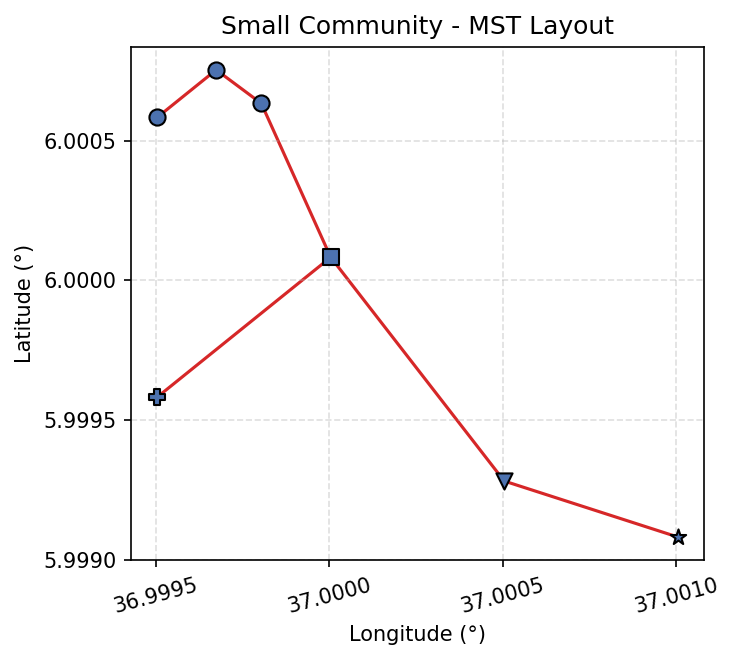

In [4]:
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
from matplotlib.ticker import FormatStrFormatter, MaxNLocator
from itertools import combinations
import os

# --- CONFIGURATION ---
SCENARIO = "small_community"
nodes_path = os.path.join("../input", SCENARIO, "nodes.csv")

# 1. Load Data
df = pd.read_csv(nodes_path)
if "node_id" not in df.columns:
    df["node_id"] = np.arange(len(df))

# 2. Build Graph and Compute MST
G = nx.Graph()
for _, row in df.iterrows():
    G.add_node(row["node_id"], pos=(row["longitude"], row["latitude"]), profile=row["load_profile_type"])

for i, j in combinations(df.index, 2):
    n1, n2 = df.loc[i, "node_id"], df.loc[j, "node_id"]
    x1, y1 = df.loc[i, "longitude"], df.loc[i, "latitude"]
    x2, y2 = df.loc[j, "longitude"], df.loc[j, "latitude"]
    dist = np.sqrt((x2 - x1)**2 + (y2 - y1)**2)
    G.add_edge(n1, n2, weight=dist)

mst = nx.minimum_spanning_tree(G, weight="weight")

# 3. Plotting
fig, ax = plt.subplots(figsize=(5, 4.5), dpi=150)
pos = {row["node_id"]: (row["longitude"], row["latitude"]) for _, row in df.iterrows()}

# Draw Edges
for u, v in mst.edges():
    ax.plot([pos[u][0], pos[v][0]], [pos[u][1], pos[v][1]], color="#D62728", linewidth=1.5, zorder=1)

# Draw Nodes
marker_map = {"hospital": "P", "health_centre": "P", "school": "*", "house": "o", "residential": "o", "commercial": "s", "water_pump": "v"}
for b_type in df["load_profile_type"].dropna().unique():
    subset = df[df["load_profile_type"] == b_type]
    ax.scatter(subset["longitude"], subset["latitude"], color="#4C72B0", s=60, 
               marker=marker_map.get(b_type, "o"), edgecolor="black", zorder=3)

# Formatting
ax.set_xlabel("Longitude (°)")
ax.set_ylabel("Latitude (°)")
ax.xaxis.set_major_locator(MaxNLocator(nbins=4))
ax.yaxis.set_major_locator(MaxNLocator(nbins=4))
ax.xaxis.set_major_formatter(FormatStrFormatter('%.4f'))
ax.yaxis.set_major_formatter(FormatStrFormatter('%.4f'))
ax.grid(True, linestyle='--', alpha=0.4)
plt.xticks(rotation=15)
plt.title(f"{SCENARIO.replace('_', ' ').title()} - MST Layout")
plt.tight_layout()
plt.show()

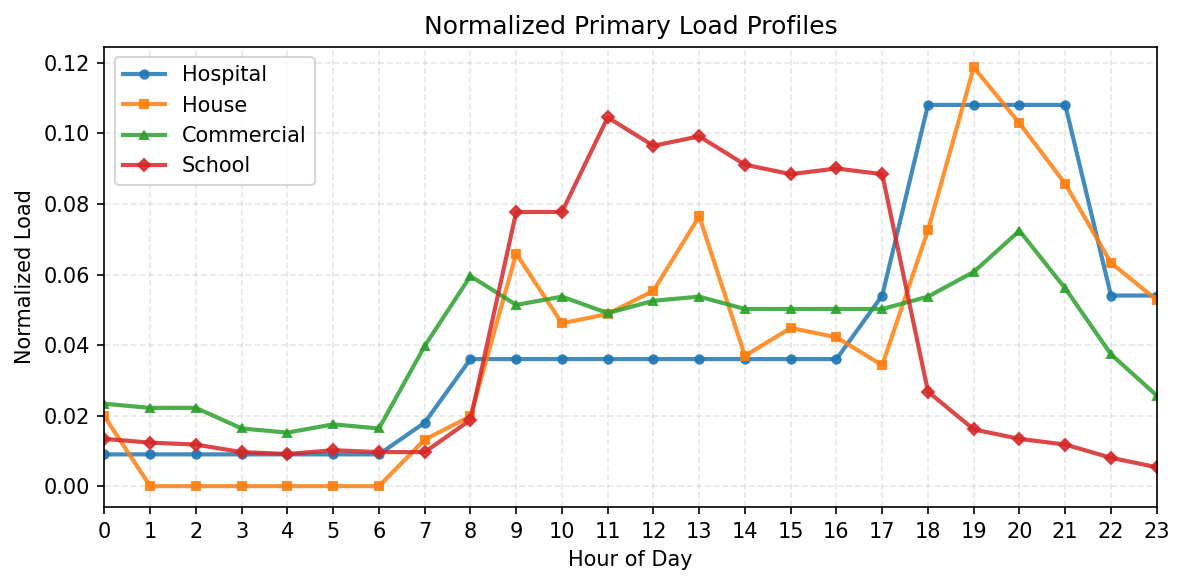

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

# --- CONFIGURATION ---
SCENARIO = "small_community"
load_path = os.path.join("../input", SCENARIO, "load.csv")

# 1. Load Data
df_load = pd.read_csv(load_path)
if "time" not in df_load.columns:
    df_load["time"] = df_load.index

# 2. Normalize Load Profiles
load_columns = [col for col in df_load.columns if col != "time" and col.lower() != "water_pump"]
df_norm = df_load.copy()

for col in load_columns:
    total_energy = df_load[col].sum()
    df_norm[col] = df_load[col] / total_energy if total_energy > 0 else df_load[col]

# 3. Plotting
fig, ax = plt.subplots(figsize=(8, 4), dpi=150)
markers = ['o', 's', '^', 'D', 'v']

for i, col in enumerate(load_columns):
    ax.plot(
        df_norm["time"], df_norm[col], 
        linestyle='-', marker=markers[i % len(markers)], markersize=4, 
        linewidth=2, alpha=0.85, label=col.replace("_", " ").title()
    )

ax.set_xlabel("Hour of Day")
ax.set_ylabel("Normalized Load")
ax.set_xlim(0, 23)
ax.set_xticks(np.arange(0, 24, 1))
ax.grid(True, linestyle='--', alpha=0.3)
ax.legend(frameon=True, loc="upper left")
plt.title("Normalized Primary Load Profiles")
plt.tight_layout()
plt.show()

In [2]:
selected_db_path = dropdown.value
storage_url = f"sqlite:///{os.path.abspath(selected_db_path)}"

summaries = optuna.get_all_study_summaries(storage=storage_url)
study = optuna.load_study(study_name=summaries[0].study_name, storage=storage_url)

print(f"Loaded Study: {study.study_name}")
if study.directions == [optuna.study.StudyDirection.MINIMIZE]:
    print(f"Best Trial Cost: ${study.best_trial.value:,.2f}")

# Optuna built-in visualisations
optuna.visualization.plot_optimization_history(study).show()
optuna.visualization.plot_param_importances(study).show()

Loaded Study: small_community_soo_isolated_20261013_120050
Best Trial Cost: $74,138.07


In [3]:
# Configuration matching your JSON batch
SCENARIO = "small_community"
OBJECTIVE = "soo"
TOPOLOGIES_TO_COMPARE = ["isolated", "mst"]

comparison_results = []
for topo in TOPOLOGIES_TO_COMPARE:
    search_path = os.path.join(base_dir, SCENARIO, "optimisation_histories", OBJECTIVE, f"*_{topo}_*.db")
    files = sorted(glob.glob(search_path), key=os.path.getmtime)
    
    if files:
        latest_file = files[-1]
        storage_url = f"sqlite:///{os.path.abspath(latest_file)}"
        study_name = optuna.get_all_study_summaries(storage=storage_url)[0].study_name
        topo_study = optuna.load_study(study_name=study_name, storage=storage_url)
        
        comparison_results.append({
            "Topology": topo.upper(),
            "Total Cost ($)": topo_study.best_trial.value
        })

if comparison_results:
    df = pd.DataFrame(comparison_results)
    fig = px.bar(df, x="Topology", y="Total Cost ($)", text_auto=".2s", 
                 color="Topology", title=f"Cost Comparison: {SCENARIO.replace('_', ' ').title()}")
    fig.update_layout(template="plotly_white")
    fig.show()
else:
    print("No databases found to compare.")